
=== Quantum Circuit (Before Measurement) ===


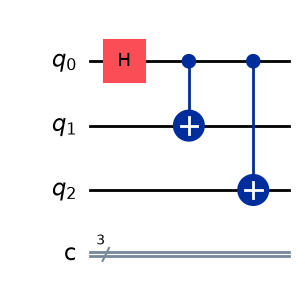


=== Statevector ===
Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.        +0.j, 0.        +0.j, 0.        +0.j,
             0.        +0.j, 0.70710678+0.j],
            dims=(2, 2, 2))

=== Q-Sphere Representation ===


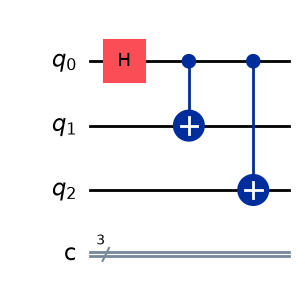

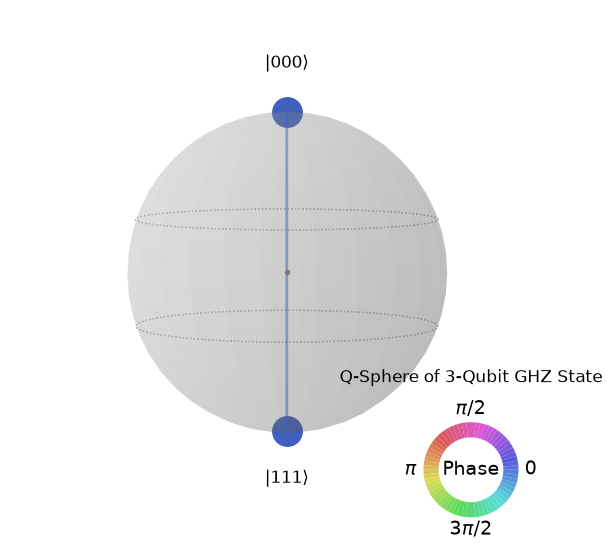


=== Bloch Sphere Representation (individual qubits) ===


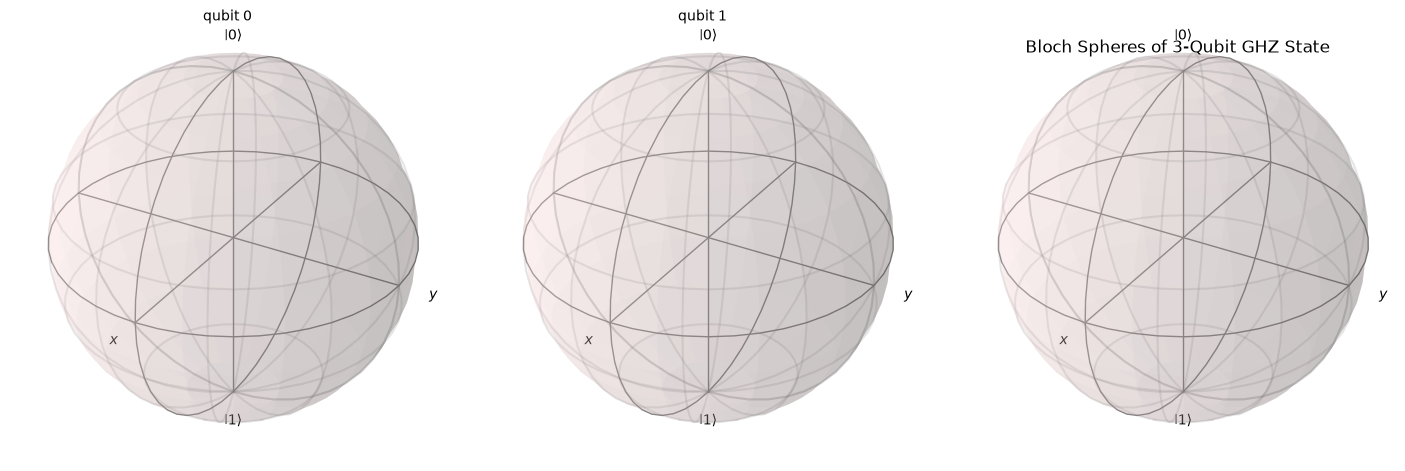


=== Quantum Circuit (With Measurement) ===


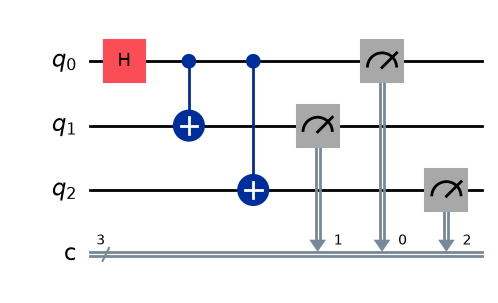


=== Measurement Results ===
{'000': 508, '111': 516}


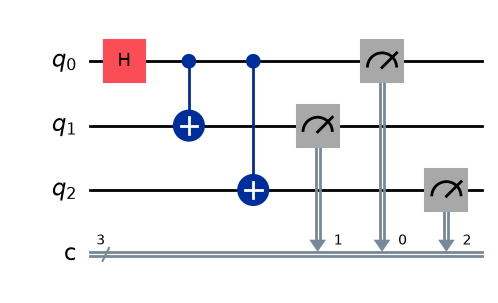

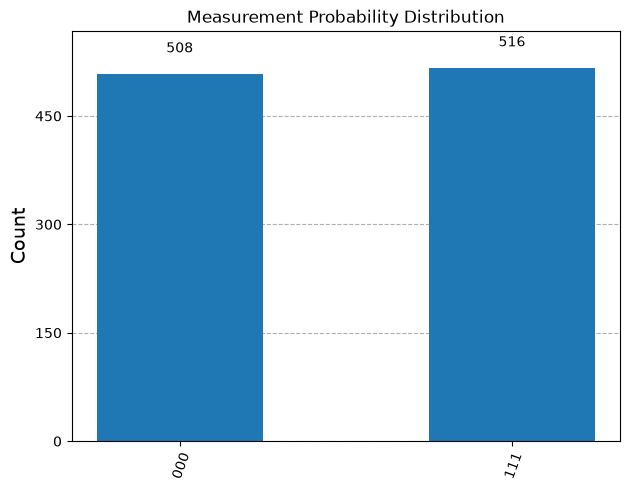

In [1]:
# ======================================================
# Qiskit Lab: 3-Qubit GHZ State
# Superposition + Entanglement + Measurement
# ======================================================

# Enable inline plotting
%matplotlib inline

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram, plot_state_qsphere, plot_bloch_multivector
from matplotlib import pyplot as plt
from IPython.display import display

# ------------------------------------------------------
# 1️⃣ Create 3-Qubit Circuit
# ------------------------------------------------------
qc = QuantumCircuit(3, 3)

# Apply Hadamard to first qubit
qc.h(0)

# Entangle remaining qubits
qc.cx(0, 1)
qc.cx(0, 2)

print("\n=== Quantum Circuit (Before Measurement) ===")
display(qc.draw("mpl"))

# ------------------------------------------------------
# 2️⃣ Statevector BEFORE Measurement
# ------------------------------------------------------
state = Statevector.from_instruction(qc)
print("\n=== Statevector ===")
print(state)

# ------------------------------------------------------
# 3️⃣ Q-Sphere Visualization
# ------------------------------------------------------
print("\n=== Q-Sphere Representation ===")
plot_state_qsphere(state)
plt.title("Q-Sphere of 3-Qubit GHZ State")
plt.show()

# ------------------------------------------------------
# 4️⃣ Bloch Sphere Visualization (individual qubits)
# ------------------------------------------------------
print("\n=== Bloch Sphere Representation (individual qubits) ===")
plot_bloch_multivector(state)
plt.title("Bloch Spheres of 3-Qubit GHZ State")
plt.show()

# ------------------------------------------------------
# 5️⃣ Add Measurement
# ------------------------------------------------------
qc.measure([0,1,2], [0,1,2])

print("\n=== Quantum Circuit (With Measurement) ===")
display(qc.draw("mpl"))

# ------------------------------------------------------
# 6️⃣ Simulation
# ------------------------------------------------------
simulator = AerSimulator()
job = simulator.run(qc, shots=1024)
result = job.result()
counts = result.get_counts()

print("\n=== Measurement Results ===")
print(counts)

# ------------------------------------------------------
# 7️⃣ Histogram
# ------------------------------------------------------
plot_histogram(counts)
plt.title("Measurement Probability Distribution")
plt.show()
